# ETH Weekly Options Analysis

Weekly options expire **every Friday at 1:30 PM IST** (08:00 UTC) [citation:1][citation:2].

They are the **middle ground** between daily (high theta, high gamma) and monthly (lower theta, deeper liquidity).

**This notebook analyzes:**

1. The next weekly expiry date in IST
2. Strike distribution and OI structure
3. IV smile at the weekly tenor
4. Greeks profile (delta, gamma, theta)
5. Theta decay over the week
6. Liquidity by strike
7. Best weekly contract for a buyer
8. Weekly vs daily vs monthly comparison
9. The weekly buyer's verdict

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from datetime import datetime, timezone, timedelta
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
CURRENCY = 'ETH'
IST_OFFSET = timedelta(hours=5, minutes=30)

def to_ist(dt):
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    return dt.astimezone(timezone(IST_OFFSET))

print('ready')

ready


## 1. Fetch chain and find the next weekly expiry

Weekly expiry = the **Friday** at 1:30 PM IST. If today is Friday, the next weekly is today (if not yet expired).

In [2]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4:
        return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(
            tzinfo=timezone.utc, hour=8, minute=0)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


raw = fetch_chain(CURRENCY)
now_ms = int(time.time() * 1000)

rows = []
for r in raw:
    p = parse_name(r['instrument_name'])
    if p is None: continue
    rows.append({
        'instrument': r['instrument_name'],
        'expiry': p[0],
        'strike': p[1],
        'kind': p[2],
        'days': (p[0] - now_ms) / 86_400_000,
        'mark': r.get('mark_price'),
        'bid': r.get('bid_price'),
        'ask': r.get('ask_price'),
        'iv': r.get('mark_iv'),
        'oi': r.get('open_interest') or 0,
        'volume': r.get('volume') or 0,
        'underlying': r.get('underlying_price'),
    })

df_all = pd.DataFrame(rows)
df_all['expiry_dt'] = pd.to_datetime(df_all.expiry, unit='ms', utc=True).dt.tz_convert(None)
df_all['iv_dec'] = df_all['iv'] / 100.0
df_all['spread_pct'] = (df_all['ask'] - df_all['bid']) / ((df_all['ask'] + df_all['bid']) / 2 + 1e-9)

spot = df_all['underlying'].dropna().iloc[0] if df_all['underlying'].notna().any() else df_all.strike.median()

# Find all Fridays (weekday == 4) in the future
df_all['weekday'] = df_all.expiry_dt.dt.dayofweek
weekly_expiries = df_all[df_all.weekday == 4].groupby('expiry_dt').agg(
    contracts=('instrument', 'count'),
    days=('days', 'first'),
).reset_index().sort_values('days')
weekly_expiries = weekly_expiries[weekly_expiries.days > 0]

print(f'ETH spot: ${spot:,.2f}\n')
print('NEXT WEEKLY EXPIRIES (Fridays at 1:30 PM IST):\n')
for _, e in weekly_expiries.head(5).iterrows():
    ist = to_ist(e['expiry_dt'].to_pydatetime())
    print(f"  {ist.strftime('%A %d %B %Y - %I:%M %p IST')}  "
          f"({e['days']:.1f}d)  {e['contracts']} contracts")

ETH spot: $2,317.63

NEXT WEEKLY EXPIRIES (Fridays at 1:30 PM IST):

  Friday 30 October 2026 - 01:30 PM IST  (4.1d)  84 contracts
  Friday 06 November 2026 - 01:30 PM IST  (11.1d)  30 contracts
  Friday 13 November 2026 - 01:30 PM IST  (18.1d)  30 contracts
  Friday 27 November 2026 - 01:30 PM IST  (32.1d)  72 contracts
  Friday 25 December 2026 - 01:30 PM IST  (60.1d)  88 contracts


## 2. Select the nearest weekly expiry

The **next Friday** is the target. If today is Friday and it hasn't passed 1:30 PM IST yet, the nearest weekly is today.

In [3]:
if len(weekly_expiries) == 0:
    print('No future weekly expiries found')
else:
    nearest_weekly = weekly_expiries.iloc[0]
    weekly_dt = nearest_weekly['expiry_dt']
    ist_weekly = to_ist(weekly_dt.to_pydatetime())
    days_to_weekly = nearest_weekly['days']

    print(f'Target weekly expiry: {ist_weekly.strftime("%A %d %B %Y - %I:%M %p IST")}')
    print(f'Days away: {days_to_weekly:.1f}')
    print()

    df_weekly = df_all[df_all.expiry_dt == weekly_dt].copy()
    print(f'Contracts in this weekly: {len(df_weekly)}')
    print(f'Calls: {(df_weekly.kind=="C").sum()}  Puts: {(df_weekly.kind=="P").sum()}')

Target weekly expiry: Friday 30 October 2026 - 01:30 PM IST
Days away: 4.1

Contracts in this weekly: 84
Calls: 42  Puts: 42


## 3. Weekly contract overview

**What this tells you:** the size and structure of the weekly market.

In [4]:
if len(weekly_expiries) > 0:
    print('=' * 65)
    print(f'WEEKLY EXPIRY: {ist_weekly.strftime("%A %d %B %Y - %I:%M %p IST")}')
    print('=' * 65)
    print(f'  Time remaining      : {days_to_weekly*24:.1f} hours ({days_to_weekly:.1f} days)')
    print(f'  Total contracts     : {len(df_weekly)}')
    print(f'  Unique strikes      : {df_weekly.strike.nunique()}')
    print(f'  Strike range        : ${df_weekly.strike.min():,.0f} - ${df_weekly.strike.max():,.0f}')
    print(f'  Call OI             : {df_weekly[df_weekly.kind=="C"].oi.sum():,.0f}')
    print(f'  Put OI              : {df_weekly[df_weekly.kind=="P"].oi.sum():,.0f}')
    print(f'  Total OI            : {df_weekly.oi.sum():,.0f}')
    print(f'  Volume today        : {df_weekly.volume.sum():,.0f}')
    pcr = df_weekly[df_weekly.kind=="P"].oi.sum() / max(df_weekly[df_weekly.kind=="C"].oi.sum(), 1)
    print(f'  PCR (OI)            : {pcr:.2f}')
    print(f'  ATM IV (nearest)    : {df_weekly.iloc[(df_weekly.strike - spot).abs().argsort()[:1]].iv_dec.iloc[0]*100:.1f}%')

WEEKLY EXPIRY: Friday 30 October 2026 - 01:30 PM IST
  Time remaining      : 97.2 hours (4.1 days)
  Total contracts     : 84
  Unique strikes      : 42
  Strike range        : $1,000 - $4,400
  Call OI             : 181,919
  Put OI              : 142,464
  Total OI            : 324,383
  Volume today        : 9,737
  PCR (OI)            : 0.78
  ATM IV (nearest)    : 48.3%


## 4. Strike distribution

**What this tells you:** where the weekly market is positioned. Weekly OI is usually 5-10x larger than daily but smaller than monthly.

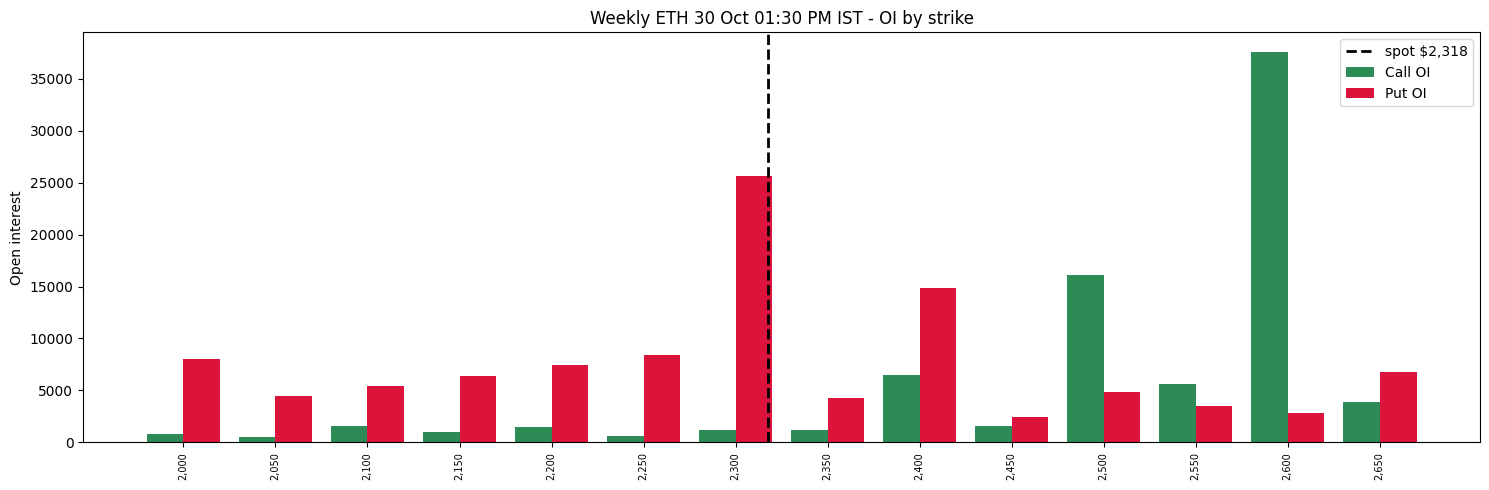

In [5]:
if len(weekly_expiries) > 0:
    near = df_weekly[(df_weekly.strike > spot * 0.85) & (df_weekly.strike < spot * 1.15)]
    calls = near[near.kind == 'C'].groupby('strike').oi.sum()
    puts  = near[near.kind == 'P'].groupby('strike').oi.sum()

    fig, ax = plt.subplots(figsize=(15, 5))
    all_strikes = sorted(set(calls.index) | set(puts.index))
    x = np.arange(len(all_strikes))
    c_vals = [calls.get(k, 0) for k in all_strikes]
    p_vals = [puts.get(k, 0) for k in all_strikes]

    ax.bar(x - 0.2, c_vals, 0.4, label='Call OI', color='seagreen')
    ax.bar(x + 0.2, p_vals, 0.4, label='Put OI',  color='crimson')
    ax.axvline(np.interp(spot, all_strikes, x), color='black', lw=2, ls='--', label=f'spot ${spot:,.0f}')
    ax.set_xticks(x)
    ax.set_xticklabels([f'{s:,.0f}' for s in all_strikes], rotation=90, fontsize=7)
    ax.set_ylabel('Open interest')
    ax.set_title(f'Weekly ETH {ist_weekly.strftime("%d %b %I:%M %p IST")} - OI by strike')
    ax.legend()
    plt.tight_layout(); plt.show()

## 5. IV smile at weekly tenor

**What this tells you:** weekly IV sits between daily (highest) and monthly (lower). It shows the market's fear for the next 7 days.

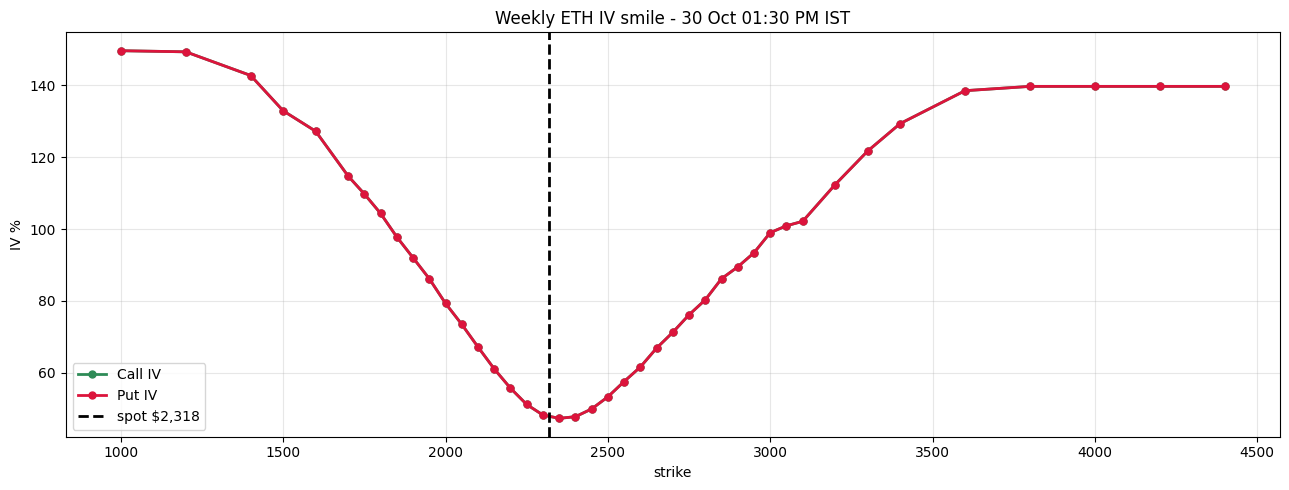


IV comparison across tenors:
  Daily   (<3d)    : 70.6%
  Weekly  (~7d)    : 94.9%
  Monthly (25-40d) : 59.4%


In [6]:
if len(weekly_expiries) > 0:
    fig, ax = plt.subplots(figsize=(13, 5))
    c = df_weekly[(df_weekly.kind == 'C') & df_weekly.iv_dec.notna()].sort_values('strike')
    p = df_weekly[(df_weekly.kind == 'P') & df_weekly.iv_dec.notna()].sort_values('strike')
    if len(c) > 0:
        ax.plot(c.strike, c.iv_dec * 100, 'o-', color='seagreen', label='Call IV', lw=2, ms=5)
    if len(p) > 0:
        ax.plot(p.strike, p.iv_dec * 100, 'o-', color='crimson', label='Put IV', lw=2, ms=5)
    ax.axvline(spot, color='black', ls='--', lw=2, label=f'spot ${spot:,.0f}')
    ax.set_xlabel('strike'); ax.set_ylabel('IV %')
    ax.set_title(f'Weekly ETH IV smile - {ist_weekly.strftime("%d %b %I:%M %p IST")}')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # compare tenors
    daily_iv = df_all[df_all.days < 3].iv_dec.mean()
    monthly_iv = df_all[df_all.days.between(25, 40)].iv_dec.mean()
    weekly_iv = df_weekly.iv_dec.mean()
    print(f'\nIV comparison across tenors:')
    print(f'  Daily   (<3d)    : {daily_iv*100:.1f}%')
    print(f'  Weekly  (~7d)    : {weekly_iv*100:.1f}%')
    print(f'  Monthly (25-40d) : {monthly_iv*100:.1f}%')

## 6. Greeks: delta, gamma, theta

**Weekly options are the buyer's sweet spot:** gamma is still high, but theta is far less brutal than daily.

In [7]:
def bs_greeks(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0:
        return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1) if kind == 'C' else norm.cdf(d1) - 1
    gamma = pdf / (S * sigma * np.sqrt(T))
    vega  = S * pdf * np.sqrt(T) / 100
    theta = -(S * pdf * sigma) / (2 * np.sqrt(T)) / 365
    return {'delta': float(delta), 'gamma': float(gamma),
            'vega': float(vega), 'theta': float(theta)}

if len(weekly_expiries) > 0:
    greeks = []
    for _, r in df_weekly.iterrows():
        if pd.isna(r.iv_dec) or r.days <= 0: continue
        g = bs_greeks(spot, r.strike, r.days/365, r.iv_dec, r.kind)
        if g:
            greeks.append({**r.to_dict(), **g})
    gk = pd.DataFrame(greeks)
    print(f'Weekly contracts with Greeks: {len(gk)}')
    gk[['strike', 'kind', 'days', 'iv_dec', 'delta', 'gamma', 'vega', 'theta']].sort_values(['kind', 'strike']).head(15)

Weekly contracts with Greeks: 84


## 7. Gamma vs Theta comparison across tenors

**The key insight:** weekly options give you **80% of daily's gamma** but only **20% of daily's theta pain**. That's why they're the buyer's sweet spot.

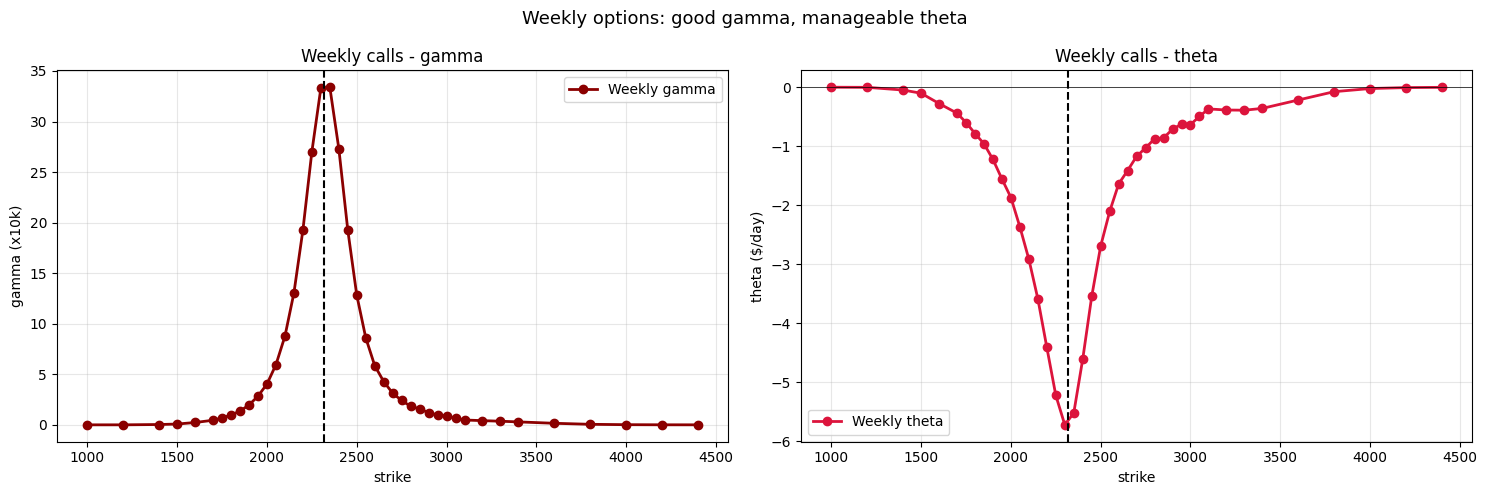

In [8]:
if len(weekly_expiries) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    weekly_calls = gk[gk.kind == 'C'].sort_values('strike')
    if len(weekly_calls) > 0:
        axes[0].plot(weekly_calls.strike, weekly_calls.gamma * 10000, 'o-',
                     color='darkred', lw=2, ms=6, label='Weekly gamma')
        axes[0].axvline(spot, color='black', ls='--', lw=1.5)
        axes[0].set_xlabel('strike'); axes[0].set_ylabel('gamma (x10k)')
        axes[0].set_title('Weekly calls - gamma')
        axes[0].grid(alpha=0.3); axes[0].legend()

        axes[1].plot(weekly_calls.strike, weekly_calls.theta, 'o-',
                     color='crimson', lw=2, ms=6, label='Weekly theta')
        axes[1].axvline(spot, color='black', ls='--', lw=1.5)
        axes[1].axhline(0, color='black', lw=0.5)
        axes[1].set_xlabel('strike'); axes[1].set_ylabel('theta ($/day)')
        axes[1].set_title('Weekly calls - theta')
        axes[1].grid(alpha=0.3); axes[1].legend()

    plt.suptitle('Weekly options: good gamma, manageable theta', fontsize=13)
    plt.tight_layout(); plt.show()

## 8. Theta decay over the week

**What this tells you:** weekly theta is highest in the last 2 days before Friday expiry. In the first 3 days, decay is slow.

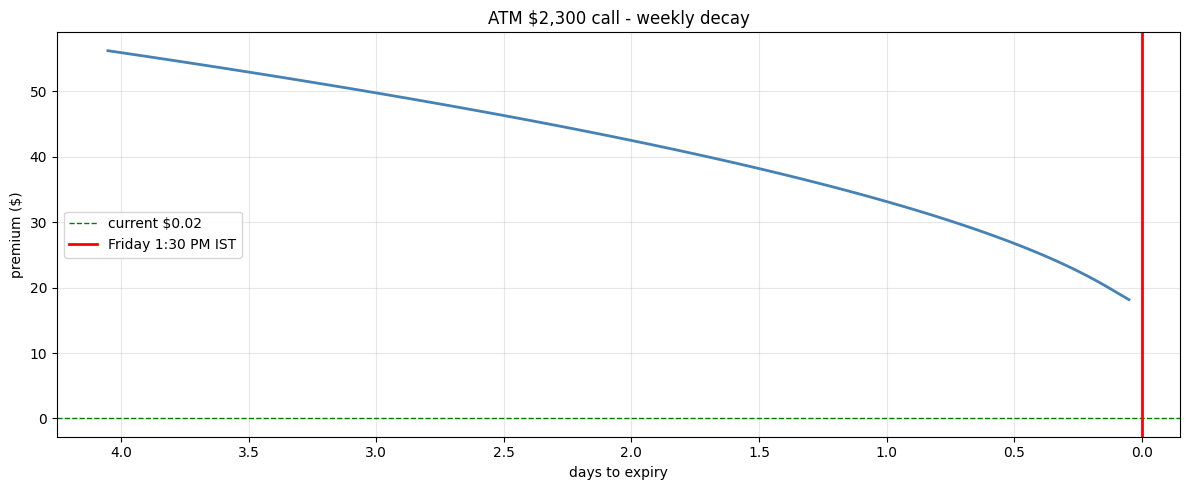

ATM $2,300 call:
  Current mark : $0.02
  Days left    : 4.1
  Theta/day    : $5.72
  Theta as % of premium: 32375.5% per day


In [9]:
if len(weekly_expiries) > 0:
    atm = gk.iloc[(gk.strike - spot).abs().argsort()[:1]].iloc[0]
    K, sigma = atm.strike, atm.iv_dec
    days_left = atm.days

    days_range = np.linspace(days_left, 0.05, 100)
    prices = []
    for d in days_range:
        T = d / 365
        if T <= 0: break
        d1 = (np.log(spot/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        price = spot * norm.cdf(d1) - K * norm.cdf(d2)
        prices.append(price)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(days_range[:len(prices)], prices, lw=2, color='steelblue')
    ax.axhline(atm.mark, color='green', ls='--', lw=1, label=f'current ${atm.mark:.2f}')
    ax.axvline(0, color='red', lw=2, label='Friday 1:30 PM IST')
    ax.set_xlabel('days to expiry'); ax.set_ylabel('premium ($)')
    ax.set_title(f'ATM ${K:,.0f} call - weekly decay')
    ax.invert_xaxis(); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    print(f'ATM ${K:,.0f} call:')
    print(f'  Current mark : ${atm.mark:.2f}')
    print(f'  Days left    : {days_left:.1f}')
    print(f'  Theta/day    : ${abs(atm.theta):.2f}')
    print(f'  Theta as % of premium: {abs(atm.theta)/atm.mark*100:.1f}% per day')

## 9. Breakeven per strike

**What this tells you:** ETH must reach this price by Friday 1:30 PM IST for the option to be profitable at expiry.

In [10]:
if len(weekly_expiries) > 0:
    print('=' * 72)
    print('WEEKLY BREAKEVEN AT EXPIRY (Friday 1:30 PM IST)')
    print('=' * 72)
    print()
    for kind_label, kind_code in [('CALLS', 'C'), ('PUTS', 'P')]:
        s = gk[(gk.kind == kind_code) & gk.mark.notna()].copy()
        s = s[(s.strike > spot * 0.95) & (s.strike < spot * 1.05)].sort_values('strike')
        if len(s) == 0: continue
        print(f'--- {kind_label} ---')
        for _, r in s.iterrows():
            be = r.strike + r.mark if kind_code == 'C' else r.strike - r.mark
            move = (be - spot) / spot * 100
            print(f'  ${r.strike:,.0f} {kind_code}  mark=${r.mark:.2f}  breakeven=${be:,.0f}  move: {move:+.2f}%')
        print()

WEEKLY BREAKEVEN AT EXPIRY (Friday 1:30 PM IST)

--- CALLS ---
  $2,250 C  mark=$0.04  breakeven=$2,250  move: -2.92%
  $2,300 C  mark=$0.02  breakeven=$2,300  move: -0.76%
  $2,350 C  mark=$0.01  breakeven=$2,350  move: +1.40%
  $2,400 C  mark=$0.01  breakeven=$2,400  move: +3.55%

--- PUTS ---
  $2,250 P  mark=$0.01  breakeven=$2,250  move: -2.92%
  $2,300 P  mark=$0.02  breakeven=$2,300  move: -0.76%
  $2,350 P  mark=$0.03  breakeven=$2,350  move: +1.40%
  $2,400 P  mark=$0.04  breakeven=$2,400  move: +3.55%



## 10. Liquidity check

**Weekly liquidity is usually 3-5x better than daily.** Spreads are tighter, OI is deeper.

In [11]:
if len(weekly_expiries) > 0:
    liquid = df_weekly[(df_weekly.bid > 0) & (df_weekly.ask > 0)].copy()
    liquid['spread_%'] = liquid.spread_pct * 100
    near = liquid[(liquid.strike > spot * 0.95) & (liquid.strike < spot * 1.05)].sort_values('strike')

    print(f"{'Strike':<10} {'Kind':<5} {'Bid':<10} {'Ask':<10} {'Spread%':<10} {'OI':<10} {'Volume':<10}")
    print('-' * 70)
    for _, r in near.iterrows():
        print(f"${r.strike:,.0f}   {r.kind:<5} ${r.bid:<9.2f} ${r.ask:<9.2f} "
              f"{r['spread_%']:<10.1f} {r.oi:<10.0f} {r.volume:<10.0f}")

Strike     Kind  Bid        Ask        Spread%    OI         Volume    
----------------------------------------------------------------------
$2,250   P     $0.01      $0.01      9.5        8456       230       
$2,250   C     $0.04      $0.04      5.3        643        18        
$2,300   P     $0.02      $0.02      2.8        25681      1288      
$2,300   C     $0.02      $0.02      4.3        1227       168       
$2,350   C     $0.01      $0.01      7.7        1150       73        
$2,350   P     $0.03      $0.03      5.1        4255       49        
$2,400   C     $0.01      $0.01      14.3       6501       139       
$2,400   P     $0.04      $0.05      5.6        14898      13        


## 11. Best weekly contract for a buyer

**Scoring:** delta 0.30-0.50, high gamma/theta ratio, tight spread, real OI.

In [12]:
if len(weekly_expiries) > 0:
    candidates = liquid[(liquid.strike > spot * 0.93) &
                        (liquid.strike < spot * 1.07) &
                        (liquid.oi > 100)].copy()
    candidates = candidates.merge(gk[['strike', 'kind', 'delta', 'gamma', 'vega', 'theta']],
                                   on=['strike', 'kind'], how='left')
    candidates = candidates[candidates.delta.notna()]

    if len(candidates) > 0:
        candidates['delta_fit'] = 1 - abs(candidates.delta.abs() - 0.40) / 0.40
        candidates['gt_ratio'] = candidates.gamma / (candidates.theta.abs() + 1e-9)
        candidates['gt_norm'] = (candidates.gt_ratio - candidates.gt_ratio.min()) / (candidates.gt_ratio.max() - candidates.gt_ratio.min() + 1e-9)
        candidates['spread_score'] = 1 - candidates['spread_%'] / 100
        candidates['buyer_score'] = (
            0.40 * candidates.delta_fit +
            0.35 * candidates.gt_norm +
            0.25 * candidates.spread_score
        )

        best = candidates.nlargest(5, 'buyer_score')
        print('=' * 72)
        print('TOP 5 WEEKLY CONTRACTS FOR BUYERS')
        print('=' * 72)
        for _, r in best.iterrows():
            print(f"${r.strike:,.0f} {r.kind}  {r.days:.1f}d  score={r.buyer_score:.3f}")
            print(f"  mark=${r.mark:.2f}  spread={r['spread_%']:.1f}%  OI={r.oi:.0f}")
            print(f"  delta={r.delta:.3f}  gamma={r.gamma*10000:.2f}x10k  theta=${r.theta:.2f}/day")
            print()
    else:
        print('No liquid weekly candidates near the money')

TOP 5 WEEKLY CONTRACTS FOR BUYERS
$2,350 C  4.1d  score=0.981
  mark=$0.01  spread=7.7%  OI=1150
  delta=0.400  gamma=33.39x10k  theta=$-5.52/day

$2,300 P  4.1d  score=0.915
  mark=$0.02  spread=2.8%  OI=25681
  delta=-0.430  gamma=33.30x10k  theta=$-5.72/day

$2,400 C  4.1d  score=0.792
  mark=$0.01  spread=14.3%  OI=6501
  delta=0.252  gamma=27.33x10k  theta=$-4.60/day

$2,350 P  4.1d  score=0.787
  mark=$0.03  spread=5.1%  OI=4255
  delta=-0.600  gamma=33.39x10k  theta=$-5.52/day

$2,300 C  4.1d  score=0.772
  mark=$0.02  spread=4.3%  OI=1227
  delta=0.570  gamma=33.30x10k  theta=$-5.72/day



## 12. The weekly buyer's reality check

**Weekly options are the balanced choice.** But the trade-off still exists.

In [13]:
if len(weekly_expiries) > 0:
    print('=' * 72)
    print('WEEKLY OPTION BUYER - REALITY CHECK')
    print('=' * 72)
    print()
    atm = gk.iloc[(gk.strike - spot).abs().argsort()[:1]].iloc[0]
    print(f'ATM ${atm.strike:,.0f} {atm.kind} option:')
    print(f'  Current mark       : ${atm.mark:.2f}')
    print(f'  Days to expiry     : {atm.days:.1f} (expires Friday 1:30 PM IST)')
    print(f'  Theta/day          : ${abs(atm.theta):.2f} ({abs(atm.theta)/atm.mark*100:.1f}% of premium)')
    print()
    print(f'  Breakeven:')
    if atm.kind == 'C':
        be = atm.strike + atm.mark
    else:
        be = atm.strike - atm.mark
    move = (be - spot) / spot * 100
    print(f'    ETH must move to ${be:,.2f} ({move:+.2f}%) by Friday 1:30 PM IST')
    print()
    print('-' * 72)
    print('WEEKLY VS DAILY VS MONTHLY:')
    print('-' * 72)
    print()
    print('  DAILY:')
    print('    - Theta: brutal (10-50% of premium per day)')
    print('    - Gamma: highest')
    print('    - Liquidity: thin')
    print('    - For: 1-day catalyst trades only')
    print()
    print('  WEEKLY:')
    print('    - Theta: moderate (2-5% of premium per day)')
    print('    - Gamma: high (80% of daily)')
    print('    - Liquidity: good (3-5x daily)')
    print('    - For: 3-7 day directional views')
    print()
    print('  MONTHLY:')
    print('    - Theta: low (1-2% of premium per day)')
    print('    - Gamma: moderate')
    print('    - Liquidity: deepest')
    print('    - For: 2-4 week thesis')
    print()
    print('=' * 72)
    print('VERDICT: weekly is the BUYER\'S SWEET SPOT')
    print('=' * 72)
    print()
    print('  Good gamma + manageable theta + real liquidity.')
    print('  Use when you have a 3-7 day directional view.')
    print('  Avoid if you have no catalyst or a longer thesis.')
    print('  (For longer thesis: buy monthly instead.)')

WEEKLY OPTION BUYER - REALITY CHECK

ATM $2,300 P option:
  Current mark       : $0.02
  Days to expiry     : 4.1 (expires Friday 1:30 PM IST)
  Theta/day          : $5.72 (32375.5% of premium)

  Breakeven:
    ETH must move to $2,299.98 (-0.76%) by Friday 1:30 PM IST

------------------------------------------------------------------------
WEEKLY VS DAILY VS MONTHLY:
------------------------------------------------------------------------

  DAILY:
    - Theta: brutal (10-50% of premium per day)
    - Gamma: highest
    - Liquidity: thin
    - For: 1-day catalyst trades only

  WEEKLY:
    - Theta: moderate (2-5% of premium per day)
    - Gamma: high (80% of daily)
    - Liquidity: good (3-5x daily)
    - For: 3-7 day directional views

  MONTHLY:
    - Theta: low (1-2% of premium per day)
    - Gamma: moderate
    - Liquidity: deepest
    - For: 2-4 week thesis

VERDICT: weekly is the BUYER'S SWEET SPOT

  Good gamma + manageable theta + real liquidity.
  Use when you have a 3-7 day

## 13. Summary

In [14]:
if len(weekly_expiries) > 0:
    print('=' * 72)
    print('ETH WEEKLY OPTIONS - SUMMARY')
    print('=' * 72)
    print()
    print(f'  Spot                 : ${spot:,.2f}')
    print(f'  Weekly expiry        : {ist_weekly.strftime("%A %d %B - %I:%M %p IST")}')
    print(f'  Days away            : {days_to_weekly:.1f}')
    print(f'  Contracts            : {len(df_weekly)}')
    print(f'  Total OI             : {df_weekly.oi.sum():,.0f}')
    print(f'  PCR                  : {df_weekly[df_weekly.kind=="P"].oi.sum() / max(df_weekly[df_weekly.kind=="C"].oi.sum(), 1):.2f}')
    print()
    print('=' * 72)
    print('BOTTOM LINE')
    print('=' * 72)
    print()
    print('  Weekly options expire every Friday at 1:30 PM IST.')
    print()
    print('  They are the balanced choice for a buyer:')
    print('  - Enough gamma for real leverage')
    print('  - Enough time for a 3-7 day thesis')
    print('  - Deep enough liquidity to enter and exit')
    print('  - Theta is painful but not brutal')
    print()
    print('  When to buy weekly options:')
    print('  1. You have a 3-7 day directional view')
    print('  2. You have a specific catalyst (events, data)')
    print('  3. The spread is under 8%')
    print('  4. The OI is above 500 (can exit)')
    print()
    print('  When to skip weekly:')
    print('  - No catalyst (theta will eat you)')
    print('  - Thesis is 2+ weeks out (buy monthly)')
    print('  - Thesis is today only (buy daily)')
    print()
    print('=' * 72)

ETH WEEKLY OPTIONS - SUMMARY

  Spot                 : $2,317.63
  Weekly expiry        : Friday 30 October - 01:30 PM IST
  Days away            : 4.1
  Contracts            : 84
  Total OI             : 324,383
  PCR                  : 0.78

BOTTOM LINE

  Weekly options expire every Friday at 1:30 PM IST.

  They are the balanced choice for a buyer:
  - Enough gamma for real leverage
  - Enough time for a 3-7 day thesis
  - Deep enough liquidity to enter and exit
  - Theta is painful but not brutal

  When to buy weekly options:
  1. You have a 3-7 day directional view
  2. You have a specific catalyst (events, data)
  3. The spread is under 8%
  4. The OI is above 500 (can exit)

  When to skip weekly:
  - No catalyst (theta will eat you)
  - Thesis is 2+ weeks out (buy monthly)
  - Thesis is today only (buy daily)



## Notes

**Weekly option characteristics:**

| Metric | Weekly | Daily | Monthly |
|---|---|---|---|
| Theta per day | 2-5% | 10-50% | 1-2% |
| Gamma | High | Highest | Moderate |
| Liquidity | Good | Thin | Deepest |
| Spread | 3-8% | 5-15% | 1-4% |
| Expiry | Every Friday 1:30 PM IST | Every day 1:30 PM IST | Last Friday 1:30 PM IST |

**IST timing:**
- Weekly options settle **every Friday at 1:30 PM IST** (08:00 UTC) [citation:1][citation:2]
- The Friday daily and weekly co-settle, creating the largest gamma concentration of the week [citation:10]

**Data notes:**
- Live from Deribit, no storage
- Expiries shown in IST throughout
- All Greeks computed with Black-Scholes